**NOTE:** standalone QC notebook for inspecting drift/motion-estimate quality. Not tied to one specific script in this folder — edit paths to point at whichever motion estimate you want to check.

In [4]:
import os
import numpy as np
import spikeinterface.full as si
import matplotlib.pyplot as plt

c:\Users\gongt\micromamba\envs\spikeinterface\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## **DEFINE FUNCTIONS** ##

In [2]:
def plot_drift_scatter(spike_times, depths, t_min=None, t_max=None, title=None):
    
    mask = np.ones(len(spike_times), dtype=bool)
    if t_min is not None:
        mask &= spike_times >= t_min
    if t_max is not None:
        mask &= spike_times <= t_max
    
    spike_times = spike_times[mask]
    depths = depths[mask]
    
    plt.figure(figsize=(15, 8))
    plt.scatter(spike_times, depths, s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title(title)
    plt.show()

In [3]:
def plot_drift_scatter_with_spatial_bins(spike_times, spike_depths, dshift, batch_size, fs, 
                                         probe_depth_min, probe_depth_max,
                                         t_min=None, t_max=None, 
                                         title='Spike Depths w/ Motion Correction'):
    if t_min is None:
        t_min = spike_times.min()
    if t_max is None:
        t_max = spike_times.max()

    n_batches, n_bins = dshift.shape
    batch_times = np.arange(n_batches) * (batch_size / fs)

    mask_drift = (batch_times >= t_min) & (batch_times <= t_max)
    batch_times_windowed = batch_times[mask_drift]
    dshift_windowed = dshift[mask_drift]  # Shape: (n_windows, n_bins)

    time_mask = (spike_times >= t_min) & (spike_times <= t_max)
    
    plt.figure(figsize=(16, 9))

    plt.scatter(spike_times[time_mask], 
                spike_depths[time_mask], 
                s=1, color='k', alpha=0.01, label='Individual Spikes')

    bin_edges = np.linspace(probe_depth_min, probe_depth_max, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2  # Center of each bin
    
    for bin_idx in range(n_bins):
        bin_center_depth = bin_centers[bin_idx]
        estimated_motion = bin_center_depth - dshift_windowed[:, bin_idx]
        
        plt.plot(batch_times_windowed, estimated_motion, 
                color='red', linewidth=2.5, alpha=0.7)
    
    plt.plot([], [], color='red', linewidth=2.5, alpha=0.7, label=f'Estimated Motion ({n_bins} spatial bins)')
    
    plt.xlabel('Time (s)')
    plt.ylabel('Depth (µm)')
    plt.title(f'{title}  [{t_min:.1f}s – {t_max:.1f}s]')
    plt.xlim(t_min, t_max)
    plt.legend(loc='upper right', fontsize=10)
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

## **LOAD DATA** ##

#### **KS** ####

In [5]:
raw_data_path = r'D:/GLC7189_c_g0/preprocessed'
kilosort_output_dir = r'E:/GLC7189_c_g0/KS4/nb10_nt0m20_car0_spc1_jobs-1_thrd4/sorter_output'
# corrected_data_path = os.path.join(kilosort_output_dir, 'temp_wh.dat')

ops = np.load(os.path.join(kilosort_output_dir, 'ops.npy'), allow_pickle=True).item()
spike_positions = np.load(os.path.join(kilosort_output_dir, 'spike_positions.npy'))
spike_times = np.load(os.path.join(kilosort_output_dir, 'spike_times.npy'))
spike_times = spike_times / ops['fs']  # Convert to seconds
before_corr_spikes = np.load(os.path.join(kilosort_output_dir, 'ks_peaks_before_correction.npy'))
# st0_drift_correction_spikes.npy shape: 
# col 0: spike times; col 1: depth (um); col 2: spike amplitude; col 3: template amplitude index; col 4: batch index ; col 5: template grid index 
peaks_combined2 = np.load(os.path.join(raw_data_path, 'thresholding_peaks', 'peaks_combined2.npy'))

print(f"ops keys: {ops.keys()}")

ops keys: dict_keys(['n_chan_bin', 'fs', 'batch_size', 'nblocks', 'Th_universal', 'Th_learned', 'tmin', 'tmax', 'nt', 'shift', 'scale', 'batch_downsampling', 'artifact_threshold', 'nskip', 'whitening_range', 'highpass_cutoff', 'binning_depth', 'sig_interp', 'drift_smoothing', 'nt0min', 'dmin', 'dminx', 'min_template_size', 'template_sizes', 'nearest_chans', 'nearest_templates', 'max_channel_distance', 'max_peels', 'templates_from_data', 'n_templates', 'n_pcs', 'Th_single_ch', 'acg_threshold', 'ccg_threshold', 'cluster_neighbors', 'cluster_downsampling', 'max_cluster_subset', 'x_centers', 'cluster_init_seed', 'duplicate_spike_ms', 'position_limit', 'filename', 'data_dir', 'settings', 'probe', 'data_dtype', 'do_CAR', 'invert_sign', 'NTbuff', 'Nchan', 'duplicate_spike_bins', 'torch_device', 'save_preprocessed_copy', 'chanMap', 'xc', 'yc', 'kcoords', 'n_chan', 'Nbatches', 'preprocessing', 'Wrot', 'fwav', 'runtime_preproc', 'usage_preproc', 'wPCA', 'wTEMP', 'yup', 'xup', 'ycup', 'xcup', 'iC

In [7]:
print(spike_positions[:1000]) # mismatch to peaks_combined2? ==> removed duplicates in ks4 

[[  22.974205 2177.8457  ]
 [  22.818563 2180.1677  ]
 [  22.35075  2174.887   ]
 ...
 [  22.079935 1063.7509  ]
 [  22.551332 1419.0908  ]
 [  24.958134 1141.1152  ]]


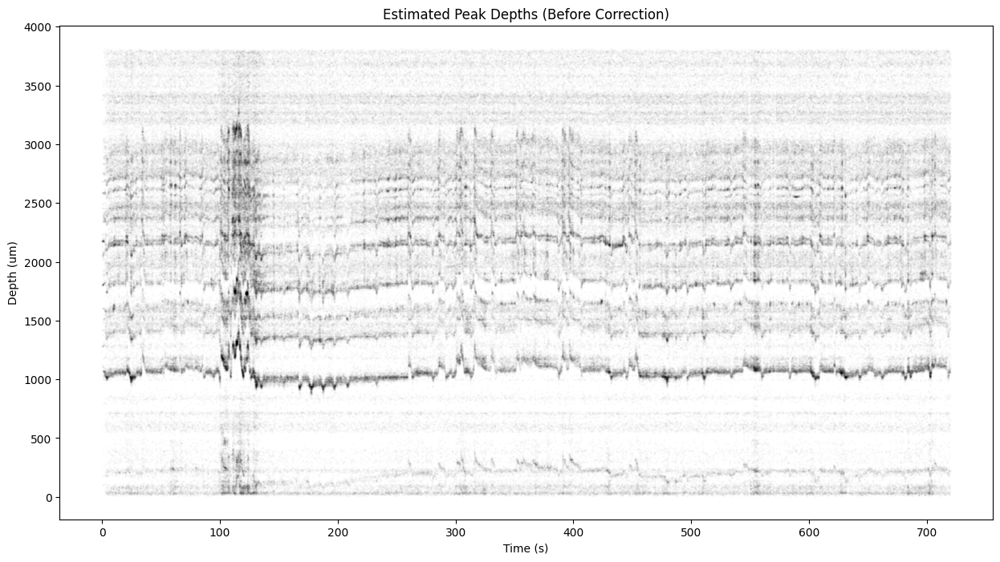

In [8]:
plot_drift_scatter(before_corr_spikes[:, 0], before_corr_spikes[:, 1], t_min = 0, t_max = 720, title='Estimated Peak Depths (Before Correction)')

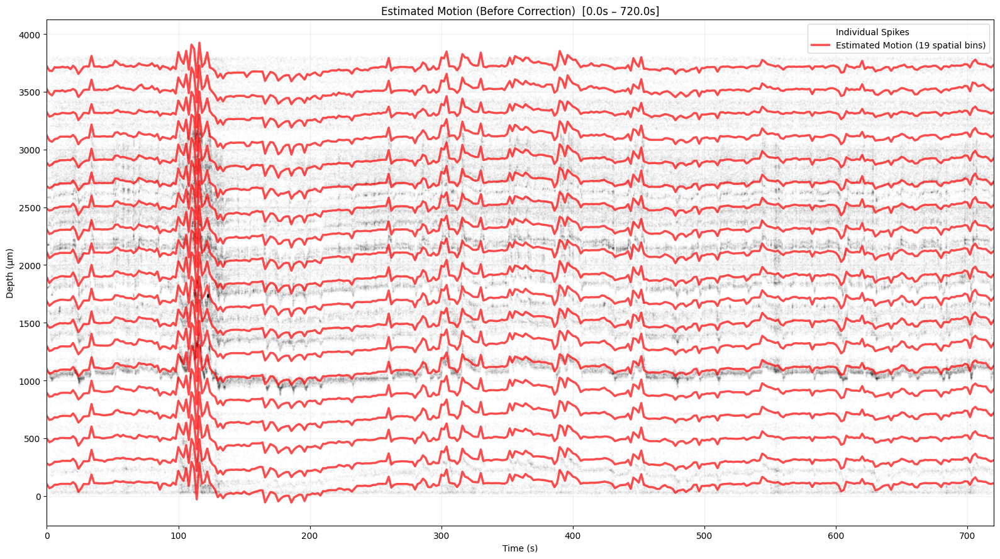

In [9]:
probe_depth_min = ops['yc'].min()
probe_depth_max = ops['yc'].max()
fs = ops['fs']

plot_drift_scatter_with_spatial_bins(
    before_corr_spikes[:, 0],  # spike times
    before_corr_spikes[:, 1],  # spike depths
    ops['dshift'],             # (1341, 9) - batches × spatial bins
    ops['batch_size'],
    fs=fs,
    probe_depth_min=probe_depth_min,
    probe_depth_max=probe_depth_max,
    t_min=0,
    t_max=720,
    title='Estimated Motion (Before Correction)'
)


In [10]:
# Apply drift correction to before_corr_spikes
print("Applying drift correction to spikes...")

before_spike_times = before_corr_spikes[:, 0]  # in seconds
before_spike_depths = before_corr_spikes[:, 1]  # in microns

batch_size = ops['batch_size']
spike_batch_idx = np.minimum(
    (before_spike_times * fs / batch_size).astype(int),
    ops['dshift'].shape[0] - 1  # Clamp to valid range
)

n_bins = ops['dshift'].shape[1]
bin_edges = np.linspace(probe_depth_min, probe_depth_max, n_bins + 1)
spike_bin_idx = np.searchsorted(bin_edges, before_spike_depths) - 1
spike_bin_idx = np.clip(spike_bin_idx, 0, n_bins - 1)  # Clamp to valid range

dshift_for_spikes = ops['dshift'][spike_batch_idx, spike_bin_idx]

corrected_depths = before_spike_depths + dshift_for_spikes


Applying drift correction to spikes...


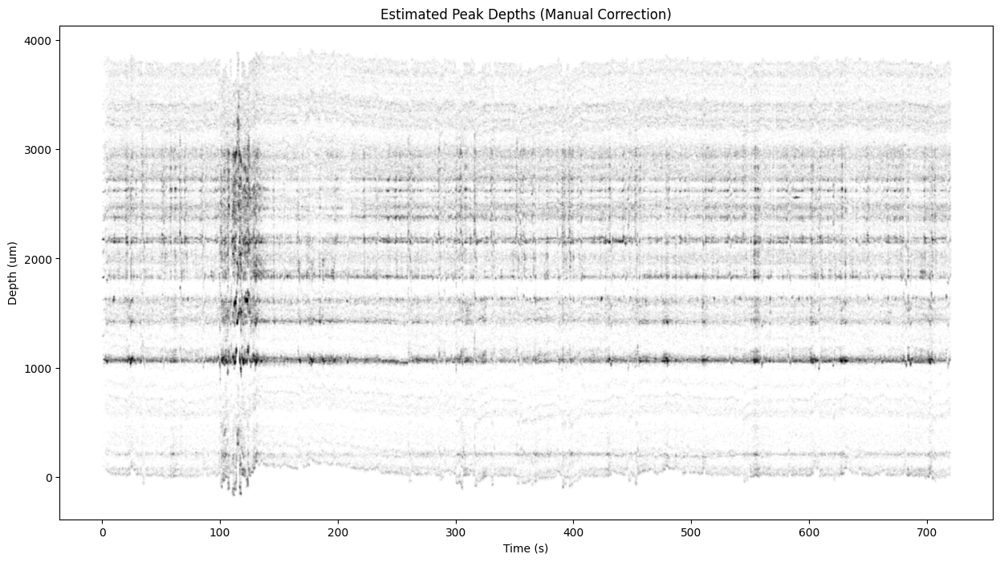

In [13]:
plot_drift_scatter(before_spike_times, corrected_depths, t_min = 0, t_max = 720, title='Estimated Peak Depths (Manual Correction)')

In [21]:
print(depths)

[2177.8457  2180.1677  2174.887   2181.127   2097.2173  2177.498
 2178.2349  2178.2058  2176.7522  2173.9487  2177.9912  1140.5022
 2173.591   2100.3342  2175.8706  1175.7198  1286.7325  1142.464
 2402.0781  3021.2666  3414.9094  2402.907   2213.8398  2407.642
 2405.2415  1026.6873  1505.0526  1111.3273  1021.22845 1137.9698
 1022.36084 2620.969   2406.7896  2175.5232  2095.3342  1502.7426
 2178.1528  2404.9558  2174.6077  2175.5566  2176.63    2175.7048
 2057.4387  2619.4858  2096.7664  1844.8906  2093.683   2177.023
 2061.65    1104.4484  1847.4644  2404.8708  1104.4495  2174.5503
 1105.1539  2402.5     2398.3828  1135.2003  2940.4207  1102.8849
  414.06677 2397.9924  1506.1412  2361.6016  2407.4365  1104.5029
 2893.4065  2887.5398  1066.2365  1063.3204  2404.543   1104.5703
 3301.8906  2403.0513  2407.3684  2379.3901  2372.6929  2175.18
 2178.2812  2403.1763  2404.2747  2617.5337  2400.497   2178.8833
 2403.6619  2176.285   2613.6553  2177.9673  2374.955   2618.639
 2737.5552  2619.

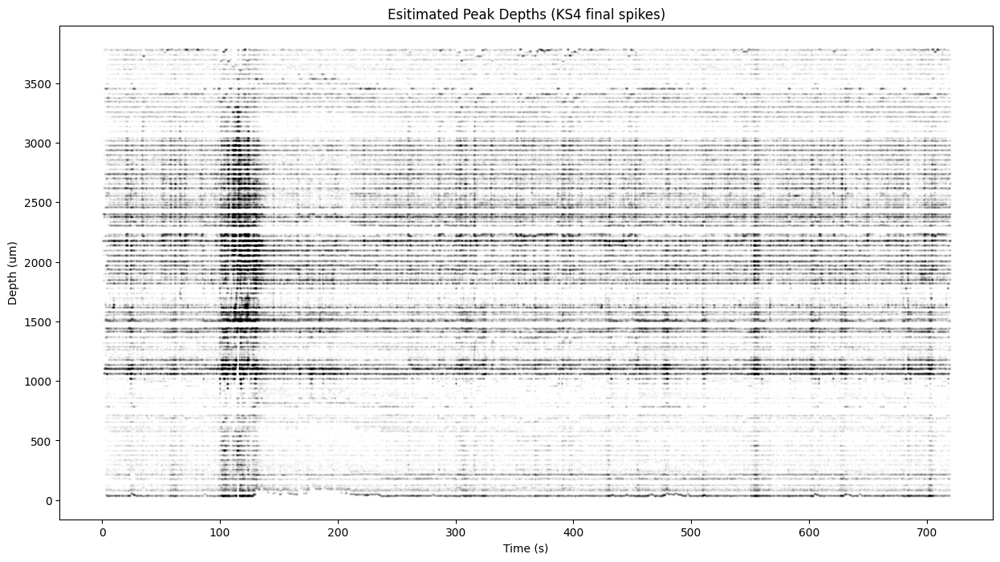

In [19]:
## final peaks ##
spike_times = np.load(os.path.join(kilosort_output_dir, 'spike_times.npy'))/ ops['fs']  # Convert to seconds
spike_positions = np.load(os.path.join(kilosort_output_dir, 'spike_positions.npy'))
depths = spike_positions[:, 1] 

plot_drift_scatter(spike_times, depths, t_min=0, t_max=720, title='Esitimated Peak Depths (KS4 final spikes)')

#### **Own** ####

In [8]:
def load_data(file_path):
    if "imec" in file_path: 
        rec = si.read_spikeglx(file_path, stream_name='imec0.ap', load_sync_channel=False) 
        rec.get_probe().to_dataframe()
    else:
        rec = si.load(file_path, n_jobs = 6)
    return rec

In [21]:
import os
import spikeinterface.full as si
import numpy as np

raw_rec_path = 'E:\GLC7189_c_g0\preprocessed'
corrected_rec_path = 'E:\GLC7189_c_g0\preprocessed/rec_corrected_dredge'
raw_rec = load_data(raw_rec_path)
# corrected_rec = load_data(corrected_rec_path)

peaks_combined2_path = os.path.join(raw_rec_path,"thresholding_peaks","peaks_combined2.npy")
peaks_combined2 = np.load(peaks_combined2_path)
peaks_combined2 = np.sort(peaks_combined2, order='sample_index')

motion_path = os.path.join(raw_rec_path,"motion_estimates")
motion_dredge = si.Motion.load(os.path.join(motion_path, "motion_dredge"))
motion_decentralized = si.Motion.load(os.path.join(motion_path, "motion_decentralized"))


In [11]:
import matplotlib.pyplot as plt
def plot_drift_scatter(peaks, peak_locations, sampling_frequency, t_min=None, t_max=None):
    times = peaks['sample_index'] / sampling_frequency
    depths = peak_locations['y']
    
    mask = np.ones(len(times), dtype=bool)
    if t_min is not None:
        mask &= times >= t_min
    if t_max is not None:
        mask &= times <= t_max
    
    times = times[mask]
    depths = depths[mask]
    
    plt.figure(figsize=(15, 8))
    plt.scatter(times, depths, s=1, color='k', alpha=0.01)
    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title('Estimated Peak Depths Over Time')
    plt.show()


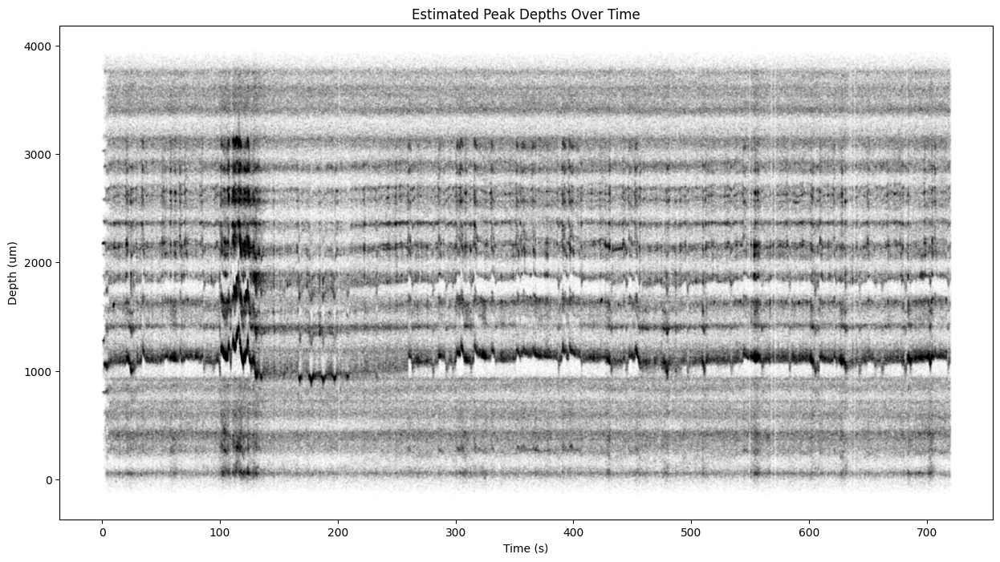

In [12]:
peak_locations_mt1 = np.load('E:\GLC7189_c_g0\preprocessed/localized_peaks_mt_raw.npy')
plot_drift_scatter(peaks_combined2, peak_locations_mt1, raw_rec.sampling_frequency, t_min=0, t_max = 12*60)

In [16]:
time_offset = raw_rec.get_times()[0]
print(time_offset)
print(raw_rec.get_times()[-1])

4.324
2889.1747666666665


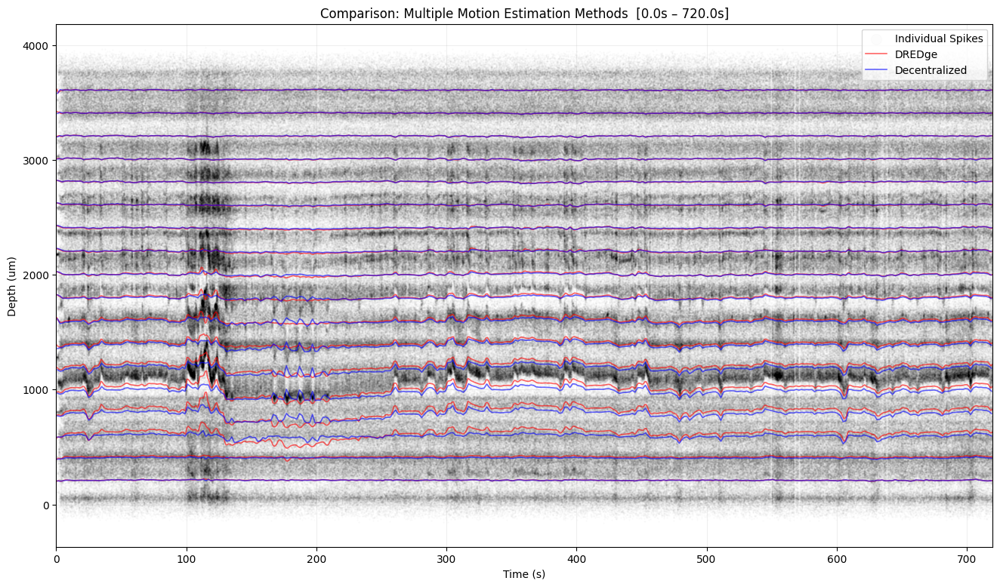

In [17]:
def plot_multi_motion_overlay(peaks, peak_locations, motion_list, labels, colors, sampling_frequency,
                               start_time=None, end_time=None):
    plt.figure(figsize=(16, 9))

    # Compute time array for peaks
    peak_times = peaks['sample_index'] / sampling_frequency

    # Set default time bounds
    if start_time is None:
        start_time = peak_times.min()
    if end_time is None:
        end_time = peak_times.max()

    # 1. Background: Raw Data (filtered by time window)
    time_mask = (peak_times >= start_time) & (peak_times <= end_time)
    plt.scatter(peak_times[time_mask],
                peak_locations['y'][time_mask],
                s=1, color='k', alpha=0.01, label='Individual Spikes')

    # 2. Iterate through each motion object provided
    for m_idx, motion_obj in enumerate(motion_list):
        color = colors[m_idx]
        label_base = labels[m_idx]

        times = [t_arr - time_offset for t_arr in motion_obj.temporal_bins_s]
        depths = motion_obj.spatial_bins_um
        displacements = motion_obj.displacement

        # Filter motion time array to the requested window
        t_arr = times[0]
        t_mask = (t_arr >= start_time) & (t_arr <= end_time)

        # Plot drift lines
        for i, start_depth in enumerate(depths):
            label = f"{label_base}" if i == 0 else ""
            drift_line = start_depth + displacements[0][:, i]

            plt.plot(t_arr[t_mask], drift_line[t_mask],
                     color=color, linewidth=1.2, alpha=0.6, label=label)

    plt.xlabel('Time (s)')
    plt.ylabel('Depth (um)')
    plt.title(f'Comparison: Multiple Motion Estimation Methods  [{start_time:.1f}s – {end_time:.1f}s]')
    plt.xlim(start_time, end_time)
    plt.legend(loc='upper right', markerscale=10)
    plt.grid(True, alpha=0.2)
    plt.show()

# Usage:
plot_multi_motion_overlay(
    peaks_combined2,
    peak_locations_mt1,
    motion_list=[motion_dredge, motion_decentralized],
    labels=['DREDge', 'Decentralized'],
    colors=['red', 'blue'],
    sampling_frequency=raw_rec.sampling_frequency,
    start_time=0*60,   # seconds — omit for full recording
    end_time=0*60+12*60      # seconds — omit for full recording
)

In [23]:
def get_manually_corrected_depths(peaks, peak_locations, motion_obj, sampling_frequency, time_offset=0):
    peak_times = (peaks['sample_index'] / sampling_frequency) + time_offset
    peak_depths_raw = peak_locations['y']
    displacements = motion_obj.get_displacement_at_time_and_depth(
        peak_times, 
        peak_depths_raw
    )

    peak_depths_corrected = peak_depths_raw - displacements
    
    return peak_depths_corrected

t_offset = raw_rec.get_times()[0]
print(f"Applying time offset of {t_offset:.4f}s to peak times...")

corrected_depths = get_manually_corrected_depths(
    peaks_combined2, 
    peak_locations_mt1, 
    motion_dredge, 
    raw_rec.sampling_frequency,
    time_offset=t_offset
)

Applying time offset of 4.3240s to peak times...


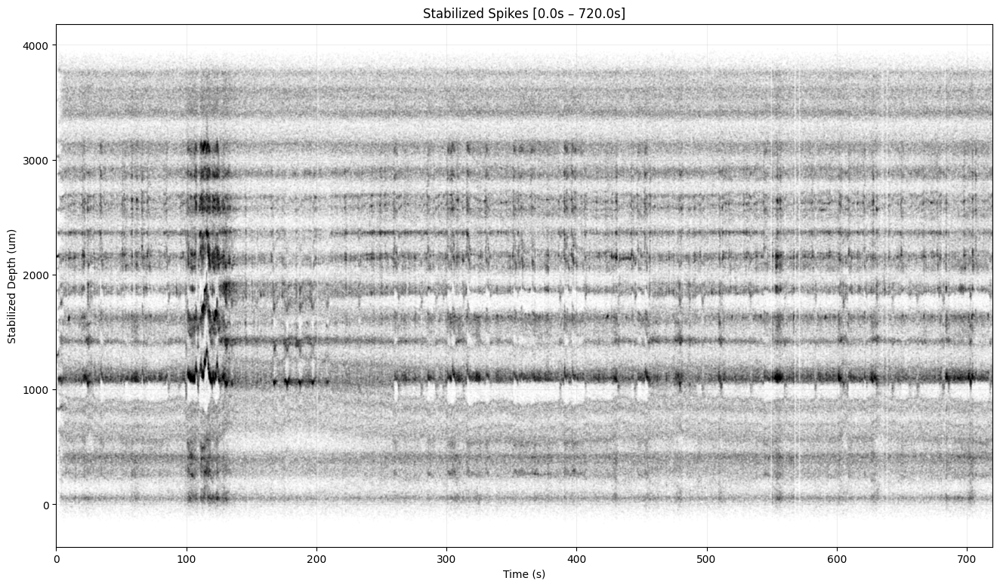

In [24]:
def plot_corrected_drift_scatter(peaks, corrected_depths, sampling_frequency, 
                                 start_time=None, end_time=None, title='Stabilized Spikes'):
    peak_times = peaks['sample_index'] / sampling_frequency
    
    if start_time is None: start_time = peak_times.min()
    if end_time is None: end_time = peak_times.max()
    
    mask = (peak_times >= start_time) & (peak_times <= end_time)
    
    plt.figure(figsize=(16, 9))
    # Using very high transparency (alpha) to see the 'density' of clusters
    plt.scatter(peak_times[mask], corrected_depths[mask], 
                s=1, color='k', alpha=0.01)
    
    plt.xlabel('Time (s)')
    plt.ylabel('Stabilized Depth (um)')
    plt.title(f'{title} [{start_time:.1f}s – {end_time:.1f}s]')
    plt.xlim(start_time, end_time)
    plt.grid(True, alpha=0.2)
    plt.show()

# Usage
plot_corrected_drift_scatter(
    peaks_combined2, 
    corrected_depths, 
    raw_rec.sampling_frequency,
    start_time=0,
    end_time=720 # 12 minutes
)

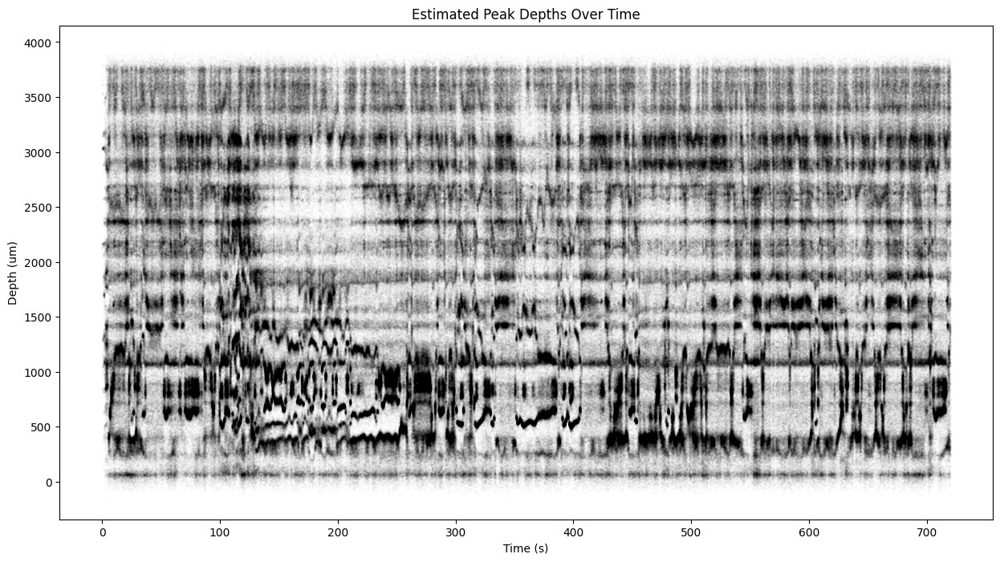

In [13]:
peaks_here = np.load('E:\GLC7189_c_g0\preprocessed/rec_corrected_dredge/thresholding_peaks/peaks_combined2.npy')
peak_locations_mt2 = np.load('E:\GLC7189_c_g0\preprocessed/rec_corrected_dredge/localized_peaks_mt_corrected.npy')
plot_drift_scatter(peaks_here, peak_locations_mt2, raw_rec.sampling_frequency, t_min=0, t_max = 12*60)

#### **Check Raw data** ####

In [6]:
def plot_spike_local_areas(
    rec,
    peaks_sets,
    bio_windows,
    noise_levels,
    detect_threshold,
    t_start,
    t_end,
    chan_start,
    chan_end,
    labels=None,
    shade_color='gray',
    save_path=None
):
    COLORS = [
        '#e6194b', '#4363d8', '#3cb44b', '#f58231', '#911eb4',
        '#42d4f4', '#f032e6', '#bfef45', '#fabed4', '#469990',
    ]

    if labels is None:
        labels = [f"Set {i+1}" for i in range(len(peaks_sets))]

    fs    = rec.sampling_frequency
    chans = rec.get_channel_ids()

    start_frame      = int(t_start * fs)
    end_frame        = int(t_end   * fs)
    chan_ids_to_plot  = chans[chan_start:chan_end]

    # Traces are only fetched for the small plot window — already fine
    traces = rec.get_traces(
        start_frame=start_frame,
        end_frame=end_frame,
        channel_ids=chan_ids_to_plot
    )

    abs_thresholds = noise_levels * detect_threshold
    num_chans      = len(chan_ids_to_plot)
    duration       = t_end - t_start

    plt.figure(figsize=(duration * 180, num_chans * 0.4))

    max_amp = np.max(np.abs(traces))
    spacing = max_amp * 1.5 if max_amp > 0 else 100
    offsets = np.arange(num_chans) * -spacing

    time_axis = np.linspace(t_start, t_end, traces.shape[0])

    for i in range(traces.shape[1]):
        abs_chan_idx = chan_start + i
        thresh       = abs_thresholds[abs_chan_idx]
        plt.plot(time_axis, traces[:, i] + offsets[i], color='black', lw=0.5)
        plt.axhline(y=-thresh + offsets[i], color='blue', ls='--', lw=0.6, alpha=0.4)

    if bio_windows is not None:
        start_frame_plot = int(t_start * fs)
        end_frame_plot   = int(t_end   * fs)

        bw_t_starts = [w['t_start'] for w in bio_windows]
        hi = bisect.bisect_right(bw_t_starts, end_frame_plot)
        lo = bisect.bisect_left(bw_t_starts, start_frame_plot)
        while lo > 0 and bio_windows[lo - 1]['t_end'] >= start_frame_plot:
            lo -= 1

        for win in bio_windows[lo:hi]:
            t0 = win['t_start'] / fs
            t1 = win['t_end']   / fs
            c0 = win['c_low']
            c1 = win['c_high']

            if c1 < chan_start or c0 >= chan_end:
                continue

            local_c0 = max(c0, chan_start) - chan_start
            local_c1 = min(c1, chan_end - 1) - chan_start

            y_top = offsets[local_c0]
            y_bot = offsets[local_c1]

            plt.fill_betweenx(
                [y_bot - spacing * 0.5, y_top + spacing * 0.5],
                max(t0, t_start),
                min(t1, t_end),
                color=shade_color,
                alpha=0.25
            )

    for set_idx, peaks in enumerate(peaks_sets):
        color   = COLORS[set_idx % len(COLORS)]
        label   = labels[set_idx]
        y_shift = set_idx * (spacing * 0.15)

        p_times  = peaks['sample_index'] / fs
        t_mask   = (p_times >= t_start) & (p_times <= t_end)
        c_mask   = (peaks['channel_index'] >= chan_start) & (peaks['channel_index'] < chan_end)
        filtered = peaks[t_mask & c_mask]

        if len(filtered) > 0:
            p_times_f      = filtered['sample_index'] / fs
            local_chan_idx = filtered['channel_index'] - chan_start
            p_pos          = filtered['amplitude'] + offsets[local_chan_idx] - y_shift
            plt.scatter(p_times_f, p_pos, color=color, s=10, zorder=3 + set_idx, label=label)

    locations   = rec.get_channel_locations()
    depths      = locations[chan_start:chan_end, 1]
    depth_labels = [int(d) for d in depths]
    plt.yticks(offsets, depth_labels)

    plt.xlim(t_start, t_end)
    plt.xlabel("Time (s)")
    plt.ylabel("depth (um)")
    plt.title(f"Spike Detection  –  Threshold: {detect_threshold}σ")
    plt.grid(axis='x', alpha=0.1)
    plt.legend(loc='upper right', markerscale=2)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")

    plt.show()



In [42]:
origianl_path = r'E:/GLC7189_c_g0/preprocessed'
#corrected_path = r'E:/GLC6962_g_g0/preprocessed/rec_corrected_dredge_ths120'
orig_rec = load_data(origianl_path)
#corrected_rec = load_data(corrected_path)
peaks_orig = np.load(os.path.join(origianl_path, 'thresholding_peaks', 'peaks_combined2.npy'))
peaks_ks4_times = np.load(os.path.join(r'E:/GLC7189_c_g0/KS4/nb10_nc32_car0_jobs-1_thrd4_ownpks/sorter_output', 'spike_times.npy'))
peaks_ks4_positions = np.load(os.path.join(r'E:/GLC7189_c_g0/KS4/nb10_nc32_car0_jobs-1_thrd4_ownpks/sorter_output', 'spike_positions.npy'))
#peaks_corrected = np.load(os.path.join(corrected_path, 'thresholding_peaks', 'peaks_combined2.npy'))

detect_threshold = 3.3

In [40]:
print(peaks_orig[:10])
#print(peaks_corrected.shape)

[( 12, 347, -3.27734375, 0, 0.) ( 82, 209, -4.93359375, 0, 0.)
 (201, 209, -3.45117188, 0, 0.) (236, 301, -3.03710938, 0, 0.)
 (288, 208, -3.94335938, 0, 0.) (347, 181, -4.60546875, 0, 0.)
 (368, 210, -3.30078125, 0, 0.) (619, 214, -3.57226562, 0, 0.)
 (824, 122, -3.11328125, 0, 0.) (828,  96, -3.22070312, 0, 0.)]


In [38]:
print(peaks_ks4_times[:10])
print(peaks_ks4_positions[:10])

[  2  72 191 226 278 337 358 609 814 818]
[[  22.606567 3605.622   ]
 [  23.49924  2177.302   ]
 [  25.246216 2192.7163  ]
 [  23.898172 3139.2598  ]
 [  24.45369  2169.5405  ]
 [  27.034748 1851.1897  ]
 [  26.735392 2222.3945  ]
 [  27.435013 2233.5828  ]
 [  24.486525 1282.2717  ]
 [  24.74533  1053.4983  ]]


In [45]:
# Convert (peaks_ks4_times, peaks_ks4_positions) → structured array matching peaks_orig format
# peaks_ks4_positions columns: [x_um, y_um]
# Need channel_index: find nearest probe channel for each spike position

chan_locs = orig_rec.get_channel_locations()   # (n_chans, 2)  [x, y]

# Nearest-channel assignment via chunked broadcasting (memory-safe)
_chunk = 200_000
n_ks4  = len(peaks_ks4_times)
channel_idx_ks4 = np.empty(n_ks4, dtype=np.int64)

for i in range(0, n_ks4, _chunk):
    sl   = slice(i, i + _chunk)
    dx   = peaks_ks4_positions[sl, 0:1] - chan_locs[:, 0]  # (chunk, n_chans)
    dy   = peaks_ks4_positions[sl, 1:2] - chan_locs[:, 1]
    channel_idx_ks4[sl] = (dx**2 + dy**2).argmin(axis=1)

# Build structured array with same dtype as peaks_orig
peaks_ks4 = np.zeros(n_ks4, dtype=[
    ('sample_index',  '<i8'),
    ('channel_index', '<i8'),
    ('amplitude',     '<f8'),
    ('segment_index', '<i8'),
])
peaks_ks4['sample_index']  = peaks_ks4_times
peaks_ks4['channel_index'] = channel_idx_ks4
peaks_ks4['amplitude']     = 0.0   # KS4 doesn't export per-spike amplitude here
peaks_ks4['segment_index'] = 0

print(f"peaks_ks4 shape: {peaks_ks4.shape}")
print(f"channel range: {peaks_ks4['channel_index'].min()} – {peaks_ks4['channel_index'].max()}")
print(peaks_ks4[:3])

peaks_ks4 shape: (9405238,)
channel range: 4 – 364
[(  2, 345, 0., 0) ( 72, 208, 0., 0) (191, 209, 0., 0)]


In [52]:
# Enrich peaks_ks4 with amplitudes and align sample_index to peaks_orig convention
sorter_output_dir = r'E:/GLC7189_c_g0/KS4/nb10_nc32_car0_jobs-1_thrd4_ownpks/sorter_output'

ks4_amps = np.load(os.path.join(sorter_output_dir, 'amplitudes.npy')).ravel().astype(np.float64)
print(f"amplitudes.npy  shape={ks4_amps.shape}  range=[{ks4_amps.min():.1f}, {ks4_amps.max():.1f}]")

# peaks_ks4['sample_index'] is peaks_orig - 10 (KS4 internal offset).
# Correct back to same convention as peaks_orig for accurate time positioning.
peaks_ks4_plot = peaks_ks4.copy()
peaks_ks4_plot['sample_index'] = peaks_ks4_times   # +10
peaks_ks4_plot['amplitude']    = -np.abs(ks4_amps)   # negative like peaks_orig threshold crossings

print(f"peaks_orig  amplitude range: [{peaks_orig['amplitude'].min():.1f}, {peaks_orig['amplitude'].max():.1f}]")
print(f"peaks_ks4   amplitude range: [{peaks_ks4_plot['amplitude'].min():.1f}, {peaks_ks4_plot['amplitude'].max():.1f}]")
print(f"peaks_ks4_plot ready: {len(peaks_ks4_plot):,} spikes")

print(f"peaks_ks4_plot ready: {len(peaks_ks4_plot):,} spikes")

amplitudes.npy  shape=(9405238,)  range=[10.6, 117.1]
peaks_orig  amplitude range: [-29.5, 0.3]
peaks_ks4   amplitude range: [-117.1, -10.6]
peaks_ks4_plot ready: 9,405,238 spikes
peaks_ks4_plot ready: 9,405,238 spikes


Plot saved to: C:/Users/gongt/Desktop/check_ks4_vs_orig.png


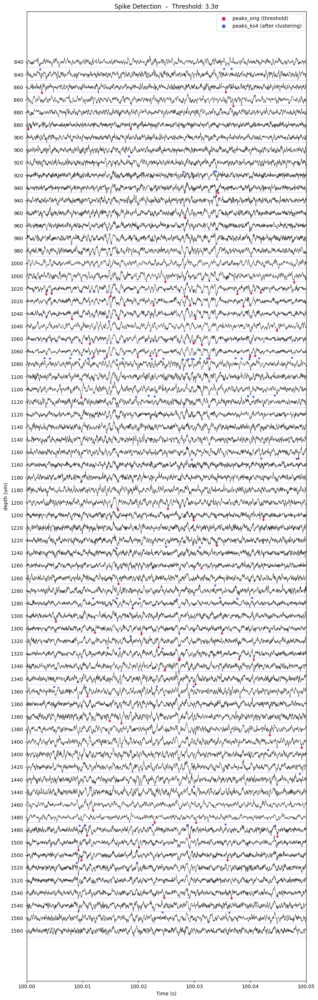

In [53]:
plot_start_s  = 100
channel_start = 80
plot_duration = 0.05
channel_end   = 150

# Scale KS4 amplitudes to the same display range as peaks_orig
# (KS4 amplitudes.npy are in template units; peaks_orig are in raw data units)
scale = np.abs(np.median(peaks_orig['amplitude'])) / np.median(np.abs(peaks_ks4_plot['amplitude']))
peaks_ks4_display = peaks_ks4_plot.copy()
peaks_ks4_display['amplitude'] = peaks_ks4_plot['amplitude'] * scale

plot_spike_local_areas(
    rec=orig_rec,
    peaks_sets=[peaks_orig, peaks_ks4_display],
    labels=['peaks_orig (threshold)', 'peaks_ks4 (after clustering)'],
    noise_levels=noise_levels,
    bio_windows=None,
    detect_threshold=detect_threshold,
    t_start=plot_start_s,
    t_end=plot_start_s + plot_duration,
    chan_start=channel_start,
    chan_end=channel_end,
    shade_color='salmon',
    save_path="C:/Users/gongt/Desktop/check_ks4_vs_orig.png"
)

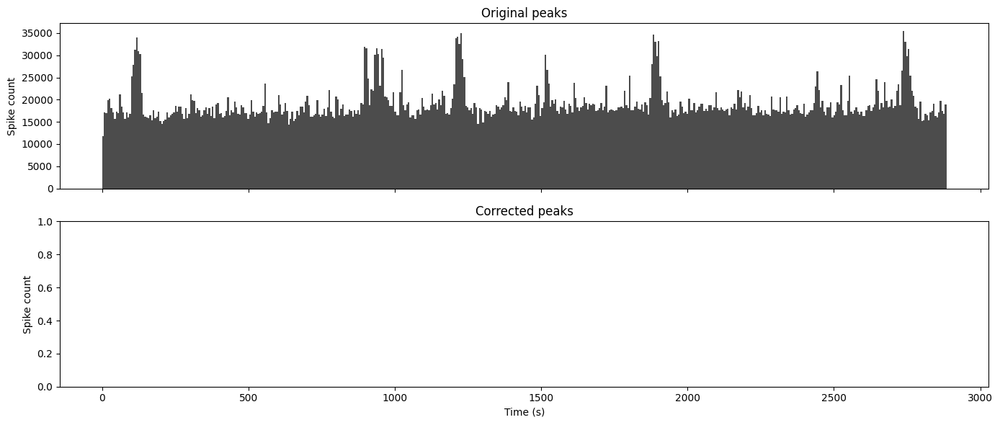

In [28]:
fs = orig_rec.sampling_frequency

times_orig = peaks_orig['sample_index'] / fs
#times_corrected = peaks_corrected['sample_index'] / fs

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].hist(times_orig, bins=500, color='k', alpha=0.7)
axes[0].set_ylabel('Spike count')
axes[0].set_title('Original peaks')

#axes[1].hist(times_corrected, bins=500, color='steelblue', alpha=0.7)
axes[1].set_ylabel('Spike count')
axes[1].set_title('Corrected peaks')

axes[1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

In [29]:
noise_levels = si.get_noise_levels(orig_rec, return_in_uV=False)

noise_level (no parallelization): 100%|██████████| 20/20 [00:05<00:00,  3.64it/s]


Plot saved to: C:/Users/gongt/Desktop/check_71892.png


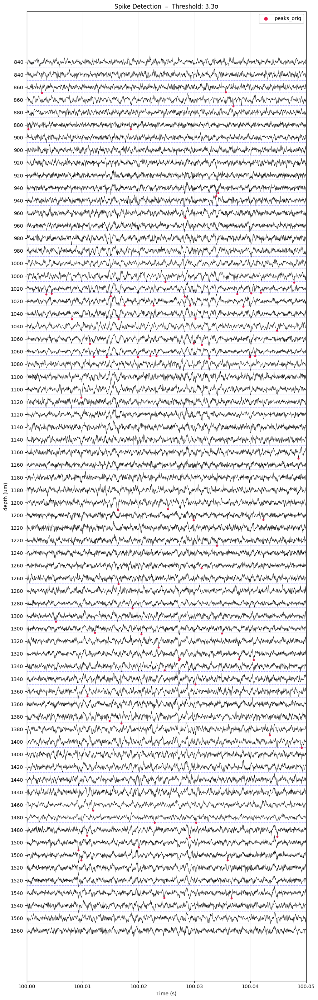

In [30]:
plot_start_s    = 100
channel_start   = 80
plot_duration   = 0.05
channel_end     = 150

plot_spike_local_areas(
    rec=orig_rec,
    peaks_sets=[peaks_orig],
    labels=['peaks_orig'],
    noise_levels=noise_levels,
    bio_windows=None,
    detect_threshold=detect_threshold,
    t_start=plot_start_s,
    t_end=plot_start_s + plot_duration,
    chan_start=channel_start,
    chan_end=channel_end,
    shade_color='salmon',
    #save_path=os.path.join(bin_path, "thresholding_peaks", "plot2.png")
    save_path="C:/Users/gongt/Desktop/check_71892.png")

Plot saved to: C:/Users/gongt/Desktop/check1.png


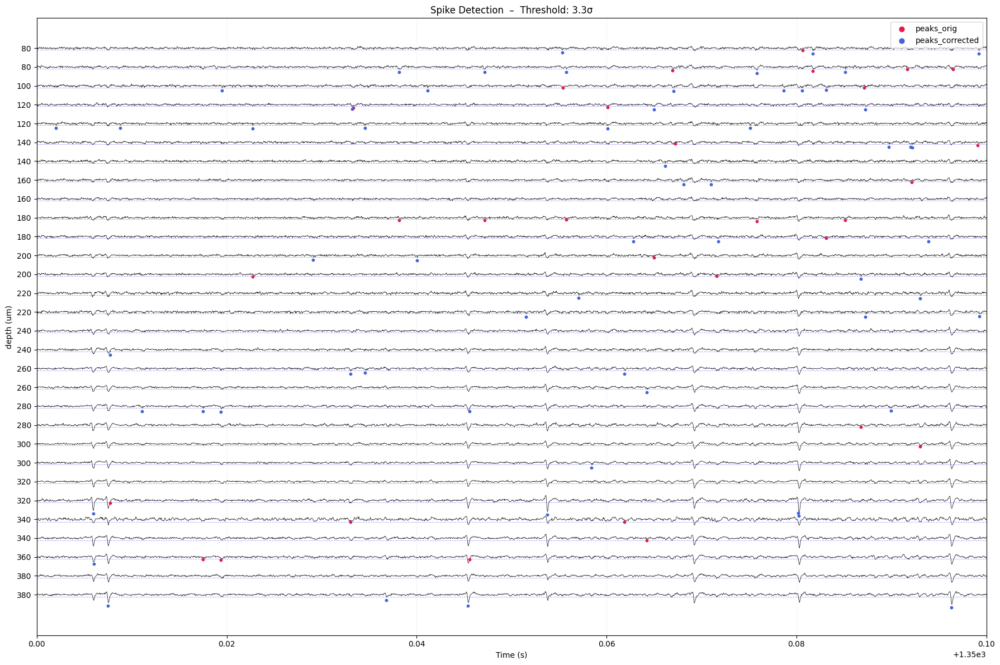

In [17]:
plot_start_s    = 1350
channel_start   = 0
plot_duration   = 0.1
channel_end     = 30

plot_spike_local_areas(
    rec=corrected_rec,
    peaks_sets=[peaks_orig, peaks_corrected],
    labels=['peaks_orig', 'peaks_corrected'],
    noise_levels=noise_levels2,
    bio_windows=None,
    detect_threshold=detect_threshold,
    t_start=plot_start_s,
    t_end=plot_start_s + plot_duration,
    chan_start=channel_start,
    chan_end=channel_end,
    shade_color='salmon',
    #save_path=os.path.join(bin_path, "thresholding_peaks", "plot2.png")
    save_path="C:/Users/gongt/Desktop/check1.png")